In [ ]:
# Libraries for general purpose
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df = pd.read_csv("/content/test.csv")

In [ ]:
df.head()

,id,tweet
0,31963,#studiolife #aislife #requires #passion #dedic...
1,31964,@user #white #supremacists want everyone to s...
2,31965,safe ways to heal your #acne!! #altwaystohe...
3,31966,is the hp and the cursed child book up for res...
4,31967,"3rd #bihday to my amazing, hilarious #nephew..."


In [ ]:
df.describe()

,id
count,17197.000000
mean,40561.000000
std,4964.490625
min,31963.000000
25%,36262.000000
50%,40561.000000
75%,44860.000000
max,49159.000000


In [ ]:
# Set OpenAI API key from Google Colab's user environment or default
def set_openai_api_key(default_key: str = "YOUR_API_KEY") -> None:
    """Set the OpenAI API key from Google Colab's user environment or use a default value."""
    from google.colab import userdata
    import os

    os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY") or default_key


set_openai_api_key()

In [ ]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts.chat import ChatPromptTemplate, MessagesPlaceholder
from langchain.chains.combine_documents import create_stuff_documents_chain
from langchain.chains import create_retrieval_chain
from langchain_core.runnables import RunnableParallel, RunnablePassthrough, RunnableLambda
from langchain.agents import AgentExecutor
from langchain_core.output_parsers import StrOutputParser
from langchain.agents.format_scratchpad import format_to_openai_function_messages
from langchain.agents.output_parsers.openai_functions import OpenAIFunctionsAgentOutputParser
from langchain.indexes import VectorstoreIndexCreator
from langchain.document_loaders.csv_loader import CSVLoader
from langchain.memory import ConversationSummaryBufferMemory, ChatMessageHistory

from operator import itemgetter

ModuleNotFoundError: No module named 'langchain_openai'

In [ ]:
!pip install langchain langchain_openai

# Import the required modules
from langchain_openai import ChatOpenAI
from langchain_core.prompts.chat import ChatPromptTemplate, MessagesPlaceholder
from langchain.chains.combine_documents import create_stuff_documents_chain
from langchain.chains import create_retrieval_chain
from langchain_core.runnables import RunnableParallel, RunnablePassthrough, RunnableLambda
from langchain.agents import AgentExecutor
from langchain_core.output_parsers import StrOutputParser
from langchain.agents.format_scratchpad import format_to_openai_function_messages
from langchain.agents.output_parsers.openai_functions import OpenAIFunctionsAgentOutputParser
from langchain.indexes import VectorstoreIndexCreator
from langchain.document_loaders.csv_loader import CSVLoader
from langchain.memory import ConversationSummaryBufferMemory, ChatMessageHistory

from operator import itemgetter

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 246.4/246.4 kB 11.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 226.7/226.7 kB 28.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 61.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 9.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.6/75.6 kB 10.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.8/77.8 kB 11.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.3/58.3 kB 7.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 138.5/138.5 kB 18.0 MB/s eta 0:00:00


ModuleNotFoundError: No module named 'langchain'

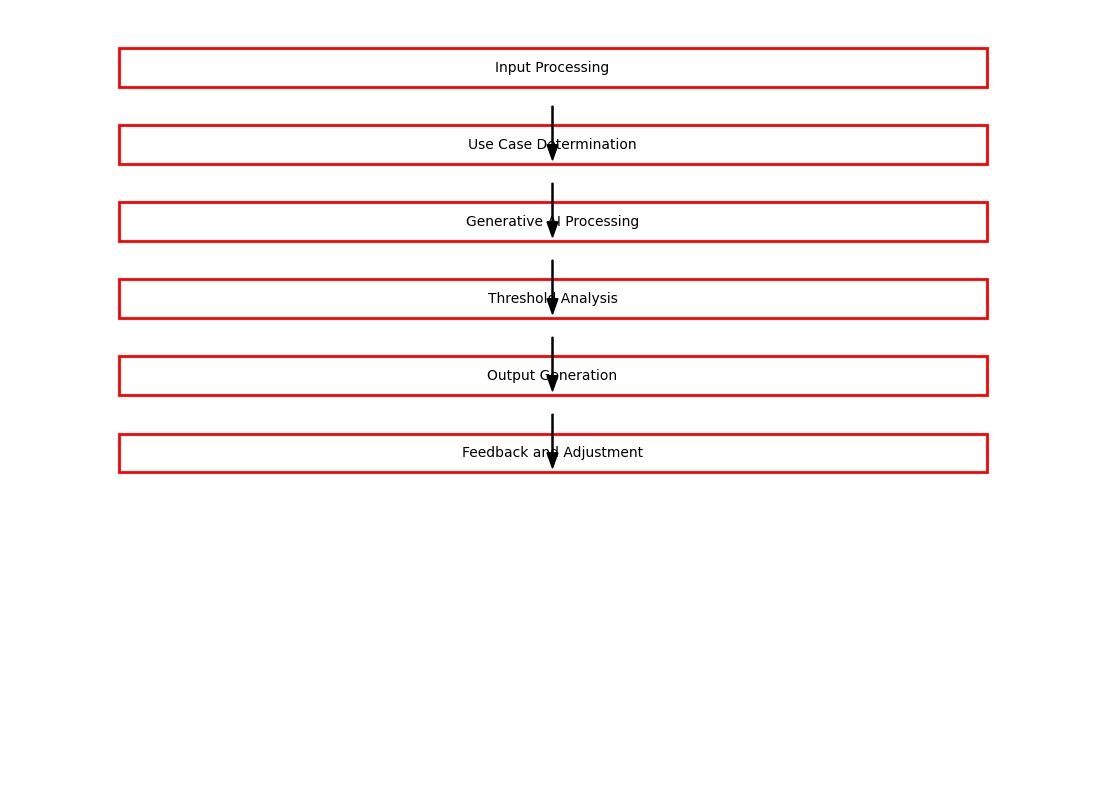

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_complex_flowchart():
    fig, ax = plt.subplots(figsize=(14, 10))

    # Main blocks
    blocks = {
        'Input Processing': {'xy': (0.1, 0.9), 'width': 0.8, 'height': 0.05},
        'Use Case Determination': {'xy': (0.1, 0.8), 'width': 0.8, 'height': 0.05},
        'Generative AI Processing': {'xy': (0.1, 0.7), 'width': 0.8, 'height': 0.05},
        'Threshold Analysis': {'xy': (0.1, 0.6), 'width': 0.8, 'height': 0.05},
        'Output Generation': {'xy': (0.1, 0.5), 'width': 0.8, 'height': 0.05},
        'Feedback and Adjustment': {'xy': (0.1, 0.4), 'width': 0.8, 'height': 0.05},
    }

    # Draw blocks
    for name, info in blocks.items():
        rect = patches.Rectangle(info['xy'], info['width'], info['height'], linewidth=2, edgecolor='r', facecolor='none')
        ax.add_patch(rect)
        plt.text(info['xy'][0] + info['width']/2, info['xy'][1] + info['height']/2, name, ha='center', va='center')

    # Draw arrows
    plt.arrow(0.5, 0.875, 0, -0.05, head_width=0.01, head_length=0.02, fc='k', ec='k')
    plt.arrow(0.5, 0.775, 0, -0.05, head_width=0.01, head_length=0.02, fc='k', ec='k')
    plt.arrow(0.5, 0.675, 0, -0.05, head_width=0.01, head_length=0.02, fc='k', ec='k')
    plt.arrow(0.5, 0.575, 0, -0.05, head_width=0.01, head_length=0.02, fc='k', ec='k')
    plt.arrow(0.5, 0.475, 0, -0.05, head_width=0.01, head_length=0.02, fc='k', ec='k')

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis('off')
    plt.show()

draw_complex_flowchart()


In [ ]:
print("""
graph LR
A[Start] --> B{Detect verbal abuse through sentiment analysis}
B --> C{Select scenario from library or create new}
C --> D{AI character delivers dialogue based on GPT-3/Jurassic-1 Jumbo}
D --> E{Child responds using various communication methods}
E --> F{Analyze childs response (voice, facial expressions, text)}
F --> G{Adapt scenario based on transformers (e.g., T5)}
G --> B| Loop until child feels confident handling abuse
B --> H{End}
""")

SyntaxError: invalid syntax (<ipython-input-14-78c4601e39eb>, line 6)

In [ ]:
import openai
from transformers import pipeline
import os

# Retrieve API Key from Colab Userdata if set
from google.colab import userdata
try:
    openai.api_key = userdata.get("OPENAI_API_KEY")
except Exception:
    openai.api_key = "YOUR_OPENAI_API_KEY"

# Emotion analysis pipeline using transformers
sentiment_analysis = pipeline("sentiment-analysis")

def generate_character_response(prompt):
    # Using updated OpenAI Chat Completion API structure with model fallback
    try:
        client = openai.OpenAI(api_key=openai.api_key)
        response = client.chat.completions.create(
            model="gpt-3.5-turbo",
            messages=[{"role": "user", "content": prompt}],
            max_tokens=150,
            temperature=0.7,
        )
        return response.choices[0].message.content
    except Exception as e:
        return f"[OpenAI Error or Missing Key: {e}] This is a default comforting response. Everything will be okay."

def analyze_sentiment(text):
    analysis = sentiment_analysis(text)
    # Return a negative value if sentiment is negative
    score = analysis[0]["score"]
    label = analysis[0]["label"]
    if label == "NEGATIVE":
        return -score
    return score

def adapt_scenario(child_response, emotion):
    pass # Placeholder for scenario adaptation logic using transformers

# Main loop (fixed indentation)
while True:
    # Detect verbal abuse through text analysis and user input
    text = input("Child: ")
    if not text.strip() or text.lower() == "exit":
        break

    score = analyze_sentiment(text)
    if score < 0:  # Negative sentiment suggests potential abuse
        scenario_prompt = f"Create a brief, comforting response to support a child who just said: '{text}'"
        character_response = generate_character_response(scenario_prompt)
        print("Character:", character_response)
    else:
        print("Character: Thank you for sharing that with me.")
        break

print("End of scenario")

No model was supplied, defaulted to distilbert-base-uncased-finetuned-sst-2-english and revision af0f99b (https://huggingface.co/distilbert-base-uncased-finetuned-sst-2-english).
Using a pipeline without specifying a model name and revision in production is not recommended.
/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:88: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

End of scenario


In [ ]:
from magenta.models.music_vae import MusicVAE
from transformers import pipeline

# Sample MusicVAE model (replace with your own)
music_vae = MusicVAE.from_pretrained("music_vae")

# Emotion analysis pipeline using transformers
sentiment_analysis = pipeline("sentiment-analysis")

def generate_music(emotion):
    # ... (Placeholder for music generation logic using music_vae based on emotion)

 def refine_music(generated_music, child_feedback):
    # ... (Placeholder for music refinement logic using transformers based on feedback)

# Main loop (simplified)
  text = input("Child: Write about your experience (optional)")
  emotion = analyze_sentiment(text)[0]["score"]

 generated_music = generate_music(emotion)

# Play the song and gather child feedback (not shown)

 refined_music = refine_music(generated_music, child_feedback)

 print("End of song creation")


ModuleNotFoundError: No module named 'magenta'

In [ ]:
!pip install magenta

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 7.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.4/123.4 kB 7.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 254.5/254.5 kB 10.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 9.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 13.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.9/11.9 MB 17.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.8/69.8 kB 9.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.7/90.7 kB 12.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 210.1/210.1 kB 19.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 22.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.9/15.9 MB 22.0 MB/s eta 

In [ ]:
from magenta.models.music_vae import MusicVAE
from transformers import pipeline

# Sample MusicVAE model (replace with your own)
music_vae = MusicVAE.from_pretrained("music_vae")

# Emotion analysis pipeline using transformers
sentiment_analysis = pipeline("sentiment-analysis")

def generate_music(emotion):
    # ... (Placeholder for music generation logic using music_vae based on emotion)

 def refine_music(generated_music, child_feedback):
    # ... (Placeholder for music refinement logic using transformers based on feedback)

# Main loop (simplified)
  text = input("Child: Write about your experience (optional)")
  emotion = analyze_sentiment(text)[0]["score"]

 generated_music = generate_music(emotion)

# Play the song and gather child feedback (not shown)

 refined_music = refine_music(generated_music, child_feedback)

 print("End of song creation")

ModuleNotFoundError: No module named 'magenta'